In [1]:
#Churn prediction model:

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression


In [4]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

In [5]:
df = pd.read_csv(data)
df.columns = df.columns.str.lower().str.replace(' ','_')
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ','_')
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [7]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']
categorical = ['gender', 'seniorcitizen', 'partner', 'dependents',
               'phoneservice', 'multiplelines', 'internetservice',
            'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
               'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
               'paymentmethod']

In [8]:
dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()
model.fit(X_train, y_train)

C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [9]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.fit_transform(val_dict)

y_pred  = model.predict_proba(X_val)[:,1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.8026969481902059)

# Accuracy and dummy model
- Evaluate the model on different threshold
- Check the accuracy of dummy baselines

In [10]:
len(y_val)

1409

In [11]:
(y_val == churn_decision).sum()

np.int64(1131)

In [12]:
1131/1409

0.8026969481902059

In [13]:
from sklearn.metrics import accuracy_score

In [14]:
thresholds = np.linspace(0,1,21)
scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t,score))
    scores.append(score)

0.00 0.274
0.05 0.510
0.10 0.592
0.15 0.667
0.20 0.710
0.25 0.739
0.30 0.760
0.35 0.772
0.40 0.785
0.45 0.794
0.50 0.803
0.55 0.801
0.60 0.796
0.65 0.786
0.70 0.766
0.75 0.744
0.80 0.734
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


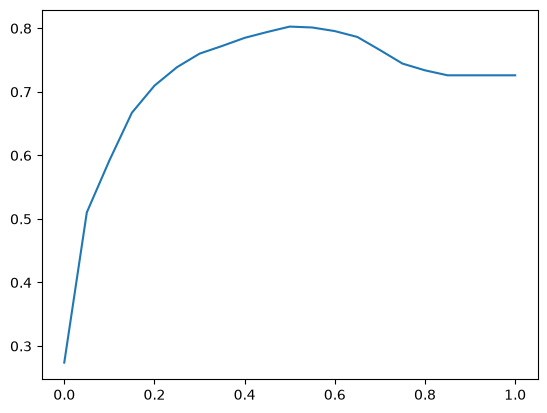

In [15]:
plt.plot(thresholds, scores)

In [16]:
from collections import Counter

In [17]:
Counter(y_pred >= 1.0)

Counter({np.False_: 1409})

# Confusion table 
- Different types of errors and correct decisions
- Arranging them in a table

In [18]:
# =============================================================================
# 4.3 CONFUSION TABLE
# =============================================================================
# Decision function score: g(x_i)
# 
# Branch 1 (Left): g(x_i) < t -> PREDICTION: NEGATIVE CLASS (NO CHURN)
#   ├── Actual: Customer Didn't Churn  -> TRUE NEGATIVE
#   └── Actual: Customer Churned       -> FALSE NEGATIVE
#
# Branch 2 (Right): g(x_i) >= t -> PREDICTION: POSITIVE CLASS (CHURN)
#   ├── Actual: Customer Didn't Churn  -> FALSE POSITIVE
#   └── Actual: Customer Churned     -> TRUE POSITIVE
# =============================================================================

In [19]:
actual_positive = (y_val ==1)
actual_negative = (y_val ==0)

In [20]:
t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [21]:
tp = (predict_positive & actual_positive).sum() #true positive
tn = (predict_negative & actual_negative).sum()  #true negative
tp, tn

(np.int64(210), np.int64(921))

In [22]:
fp = (predict_positive & actual_negative).sum() #false positive
fn = (predict_negative & actual_positive).sum()  #false negative
fp, fn

(np.int64(102), np.int64(176))

In [23]:
#now making the confusion matrix:

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[921, 102],
       [176, 210]])

In [24]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

# Precision and Recall

In [25]:
(tp + tn) / (tp + tn + fp + fn)

np.float64(0.8026969481902059)

In [26]:
p = tp / (tp + fp) #precision
p

np.float64(0.6730769230769231)

In [27]:
tp, tp+fp

(np.int64(210), np.int64(312))

In [28]:
r = tp / (tp + fn) #recall 
r

np.float64(0.5440414507772021)

In [29]:
tp, tp+fn

(np.int64(210), np.int64(386))

- as we can see, our model was having 80% (which mean pretty good) but it has:
- 67% precision value
- { precision value -> Out of all the customers the model predicted would churn , how many actually churned?
- Formula: $\text{True Positives} / (\text{True Positives} + \text{False Positives})$ }
- 54% recall value
- { recall value -> Out of all the customers who actually churned in reality, how many did the model successfully catch?
- Formula: $\text{True Positives} / (\text{True Positives} + \text{False Negatives})$}
- so we can say Accuracy of the model in classification models in not the best matric to calculate its efficiency and can be misleading.

# Receiver operating characteristics (ROC) Curves

## TPR (True positive rate) and FPR (False positive rate):

In [30]:
# =============================================================================
# CONFUSION MATRIX, FPR, AND TPR ANALYSIS
# =============================================================================
# Predictions Columns: 
#   - Negative: g(x_i) < t
#   - Positive: g(x_i) >= t
#
# Actual Rows:
#   - y = 0 (Actual Negative)
#   - y = 1 (Actual Positive)
#
# Matrix Cells & Formulas:
#   ├── TN (True Negative): Actual y=0, Predicted Negative
#   ├── FP (False Positive): Actual y=0, Predicted Positive (we want it to minimize)
#   │     └── FPR (False Positive Rate) = FP / (TN + FP)
#   ├── FN (False Negative): Actual y=1, Predicted Negative
#   └── TP (True Positive): Actual y=1, Predicted Positive (we want it to maximize)
#         └── TPR (True Positive Rate) = TP / (FN + TP)
# =============================================================================

In [31]:
tpr = tp / (tp + fn)
tpr

np.float64(0.5440414507772021)

In [32]:
fpr = fp / (fp + tn)
fpr

np.float64(0.09970674486803519)

In [33]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val ==1)
    actual_negative = (y_val ==0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    tp = (predict_positive & actual_positive).sum() #true positive
    tn = (predict_negative & actual_negative).sum()  #true negative
    fp = (predict_positive & actual_negative).sum() #false positive
    fn = (predict_negative & actual_positive).sum()  #false negative
    scores.append((t, tp, fp, fn, tn))

In [34]:
columns = ['thresholds', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns= columns)

In [35]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [36]:
df_scores[::10]

,thresholds,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,366,555,20,468,0.948187,0.542522
20,0.2,333,356,53,667,0.862694,0.347996
30,0.3,284,236,102,787,0.735751,0.230694
40,0.4,249,166,137,857,0.645078,0.162268
50,0.5,210,102,176,921,0.544041,0.099707
60,0.6,151,53,235,970,0.391192,0.051808
70,0.7,76,20,310,1003,0.196891,0.019550
80,0.8,13,2,373,1021,0.033679,0.001955
90,0.9,0,0,386,1023,0.000000,0.000000


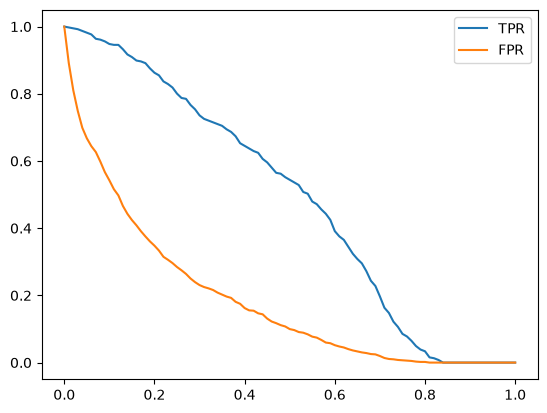

In [37]:
plt.plot(df_scores.thresholds, df_scores['tpr'], label= 'TPR')
plt.plot(df_scores.thresholds, df_scores['fpr'], label= 'FPR')
plt.legend()

## Random model

In [38]:
np.random.seed(1)
y_rand = np.random.uniform(0,1, size=len(y_val))

In [39]:
((y_rand >= 0.5) == y_val).mean()

np.float64(0.5017743080198722)

In [40]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)
    
    for t in thresholds:
        actual_positive = (y_val ==1)
        actual_negative = (y_val ==0)
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)
        tp = (predict_positive & actual_positive).sum() #true positive
        tn = (predict_negative & actual_negative).sum()  #true negative
        fp = (predict_positive & actual_negative).sum() #false positive
        fn = (predict_negative & actual_positive).sum()  #false negative
        scores.append((t, tp, fp, fn, tn))

    columns = ['thresholds', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns= columns)
    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
    return df_scores
    

In [41]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)
df_rand[::10]

,thresholds,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,202,518,184,505,0.523316,0.506354
60,0.6,161,409,225,614,0.417098,0.399804
70,0.7,121,302,265,721,0.313472,0.295210
80,0.8,78,206,308,817,0.202073,0.201369
90,0.9,40,101,346,922,0.103627,0.098729


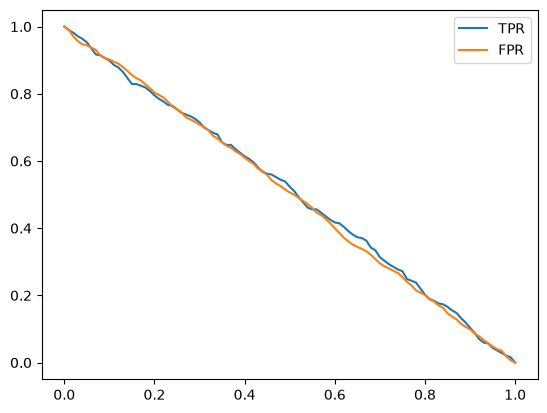

In [42]:
plt.plot(df_rand.thresholds, df_rand['tpr'], label= 'TPR')
plt.plot(df_rand.thresholds, df_rand['fpr'], label= 'FPR')
plt.legend()

## Ideal model

In [43]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
num_neg, num_pos

(np.int64(1023), np.int64(386))

In [44]:
y_ideal = np.repeat([0,1],[num_neg, num_pos])
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [45]:
y_ideal_pred = np.linspace(0,1, len(y_val))

In [46]:
1 - y_val.mean()

np.float64(0.7260468417317246)

In [47]:
((y_ideal_pred >= 0.726) == y_ideal).mean()

np.float64(1.0)

In [48]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

In [49]:
df_ideal[::10]

,thresholds,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


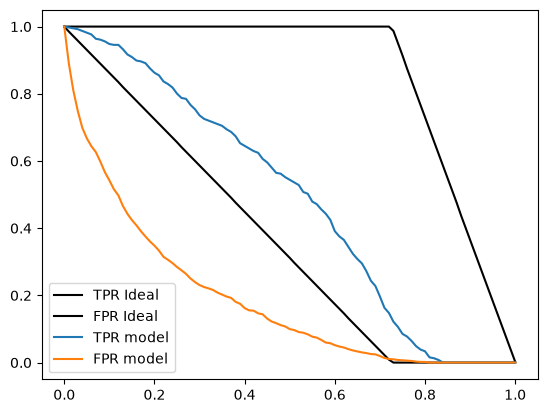

In [50]:
plt.plot(df_rand.thresholds, df_ideal['tpr'], label= 'TPR Ideal', color="black")
plt.plot(df_rand.thresholds, df_ideal['fpr'], label= 'FPR Ideal', color="black")

# plt.plot(df_rand.thresholds, df_rand['tpr'], label= 'TPR random')
# plt.plot(df_rand.thresholds, df_rand['fpr'], label= 'FPR random')

plt.plot(df_scores.thresholds, df_scores['tpr'], label= 'TPR model')
plt.plot(df_scores.thresholds, df_scores['fpr'], label= 'FPR model')

plt.legend()

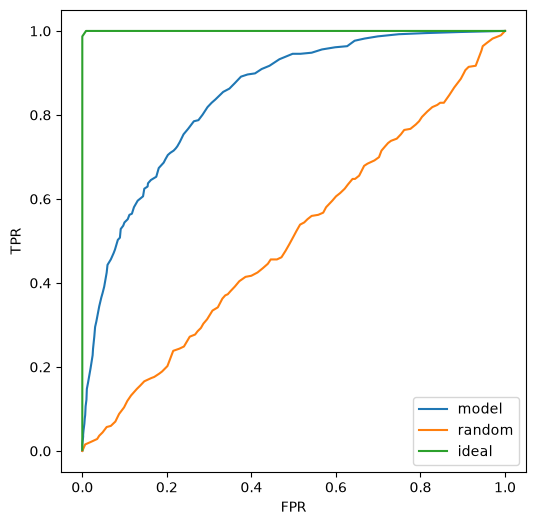

In [51]:
#ROC curve (with all data):

plt.figure(figsize=(6,6))
plt.plot(df_scores.fpr, df_scores.tpr, label="model")
plt.plot(df_rand.fpr, df_rand.tpr, label="random")
plt.plot(df_ideal.fpr, df_ideal.tpr, label="ideal")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()

In [52]:
#making ROC curve with scikit-learn:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

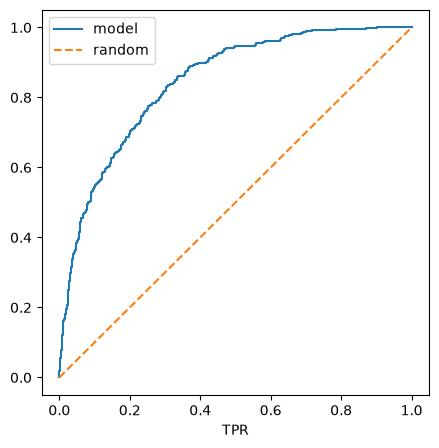

In [53]:
plt.figure(figsize=(5,5))
plt.plot(fpr, tpr, label= "model")
plt.plot([0,1], [0,1], label="random", linestyle="--")
plt.xlabel('FPR')
plt.xlabel('TPR')
plt.legend()

# ROC AUC (Area under the curve) 
- Area under the ROC curve - useful metric
- Interpretation of AUC

In [54]:
from sklearn.metrics import auc

In [55]:
auc(fpr, tpr)

0.8438150517374987

In [56]:
auc(df_scores.fpr, df_scores.tpr)

0.843869498933848

In [57]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

In [58]:
from sklearn.metrics import roc_auc_score

In [59]:
roc_auc_score(y_val, y_pred)

0.8438150517374987

In [60]:
neg = y_pred[y_val ==0 ]
pos = y_pred[y_val == 1]

In [61]:
import random

In [62]:
n = 10000
success = 0

for i in range(n):
    pos_ind = random.randint(0, len(pos) - 1)
    neg_ind = random.randint(0, len(neg) - 1)

    if pos[pos_ind] > neg[neg_ind]:
        success = success + 1 

success / n


0.8433

In [63]:
#implementing auc using numpy:
n = 50000
np.random.seed(1)
pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size=n)

In [64]:
(pos[pos_ind] > neg[neg_ind]).mean()

np.float64(0.8464)

# Cross-Validation
- Evaluating the same model on different subsets of data.
- Getting the average prediction and the spread within predictions.

In [65]:
#implementing K-Folds cross-validation

In [66]:
def train(df, y_train, C=1.0):
    dicts = df[categorical + numerical].to_dict(orient="records")

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model
    

In [67]:
dv,model = train(df_train, y_train, C=0.001)

In [68]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient="records")
    X = dv.fit_transform(dicts)
    y_pred = model.predict_proba(X)[:,1]

    return y_pred
    
    

In [69]:
y_pred = predict(df_val, dv, model)

In [70]:
from sklearn.model_selection import KFold

In [71]:
kfold = KFold(n_splits = 10, shuffle=True, random_state=1)

In [72]:
from tqdm.auto import tqdm

In [73]:
for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.churn.values
        y_val = df_val.churn.values
    
        dv,model = train(df_train, y_train, C=C)
        y_pred = predict(df_val,dv, model)
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C,np.mean(scores), np.std(scores)))


C=0.001 0.826 +- 0.012


C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=0.01 0.841 +- 0.012


C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=0.1 0.842 +- 0.012


C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=0.5 0.843 +- 0.012


C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=1 0.843 +- 0.012


C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=5 0.843 +- 0.012


C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please a

C=10 0.843 +- 0.012


C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [75]:
#training final model:
dv,model = train(df_full_train, df_full_train.churn.values , C=1.0)
y_pred = predict(df_test,dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

C:\ML-Zoomcamp-2026\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8583327916626041